# Compare vertical heating modes and heating variance

Follow the panel organization and shared Matplotlib style in **PowerSpec.ipynb**:
RH increases across columns; rows pair original and locked radiation for each
qflux. All panels within a figure share pressure and horizontal limits, with
low pressure at the top.

Load the first two total-diabatic-heating EOFs from **Output/EAPE_budget** and
convective/condensational heating variance from **Output/Heating_variance**.
EOF profiles have unit Euclidean norm and describe the shape of time-anomalous
total heating. Variance profiles pool time, latitude, and longitude samples at
each level and retain physical units of K² day⁻².

The notebook compares vertical EOF shapes (with explained variance) and plots
convective and condensational heating variance together in each experiment
panel. EOF signs are aligned before comparison. No atmospheric analysis
scripts are called.

## Import packages

In [19]:
import json
from pathlib import Path

import numpy as np
from matplotlib import pyplot as plt


## Load saved profiles

The project root is detected from the notebook's working directory, with the
current project path as a fallback. Edit the paths here for another location.
Only the saved profiles, mode coordinates, and metadata are read.

In [20]:
PROJECT_ROOT = next(
    (parent for parent in (Path.cwd(), *Path.cwd().parents)
     if (parent / "Code" / "plot_style.mplstyle").is_file()),
    Path("/home/b11209013/Isca_analysis"),
)
EAPE_DIR = PROJECT_ROOT / "Output" / "EAPE_budget"
VARIANCE_DIR = PROJECT_ROOT / "Output" / "Heating_variance"
STYLE_PATH = PROJECT_ROOT / "Code" / "plot_style.mplstyle"


def load_profiles(directory, suffix, fields):
    files = sorted(directory.glob(f"*{suffix}.npz"))
    if not files:
        raise FileNotFoundError(f"No *{suffix}.npz files found in {directory}")

    records = {}
    for file in files:
        with np.load(file, allow_pickle=False) as archive:
            name = file.stem.removesuffix(suffix)
            record = {field: np.asarray(archive[field]).copy()
                      for field in ("pfull", *fields)}
            record["metadata"] = json.loads(archive["metadata"].item())
            record["source_file"] = str(file)
        pressure = record["pfull"]
        if (pressure.ndim != 1 or pressure.size < 2
                or not np.all(np.isfinite(pressure)) or np.any(pressure <= 0)):
            raise ValueError(f"Invalid pressure coordinate in {file.name}")
        order = np.argsort(pressure)
        if np.any(np.diff(pressure[order]) <= 0):
            raise ValueError(f"Repeated pressure levels in {file.name}")
        record["pfull"] = pressure[order]
        profile_fields = ("heating_eof",) if "heating_eof" in fields else fields
        for field in profile_fields:
            if record[field].ndim < 1 or record[field].shape[-1] != pressure.size:
                raise ValueError(f"Unexpected {field} shape in {file.name}")
            record[field] = record[field][..., order]
        records[name] = record
    return records


mode_data = load_profiles(
    EAPE_DIR, "_eape", ("mode", "heating_eof", "explained_variance"),
)
variance_data = load_profiles(
    VARIANCE_DIR, "_variance", ("convection_variance", "condensation_variance"),
)

pfull = next(iter(mode_data.values()))["pfull"].copy()
modes = np.array([1, 2], dtype=np.int32)
for name, record in mode_data.items():
    if (not np.array_equal(record["mode"], modes)
            or record["heating_eof"].shape != (modes.size, pfull.size)
            or record["explained_variance"].shape != (modes.size,)
            or not np.all(np.isfinite(record["heating_eof"]))
            or np.any(np.linalg.norm(record["heating_eof"], axis=1) == 0)):
        raise ValueError(f"Expected two finite, nonzero EOF profiles for {name}")
for name, record in variance_data.items():
    for field in ("convection_variance", "condensation_variance"):
        values = record[field]
        if values.shape != (pfull.size,) or np.any(values[np.isfinite(values)] < 0):
            raise ValueError(f"Invalid {field} for {name}")
for records in (mode_data, variance_data):
    for name, record in records.items():
        pressure = record["pfull"]
        if (pressure.shape != pfull.shape
                or not np.allclose(pressure, pfull, rtol=1e-8, atol=1e-6)):
            raise ValueError(f"Pressure grid differs for {name}; no interpolation is applied")

experiment_info = {}
sampling_fields = (
    "spinup_records", "retained_time_samples", "latitude_samples",
    "longitude_samples", "latitude_min", "latitude_max", "time_start",
    "time_end", "time_units", "time_calendar",
)
for records in (mode_data, variance_data):
    for name, record in records.items():
        info = record["metadata"]
        if name in experiment_info:
            previous = experiment_info[name]
            for field in ("qflux", "rh", "rad", *sampling_fields):
                if previous.get(field) != info.get(field):
                    raise ValueError(f"{field} differs between diagnostics for {name}")
        experiment_info[name] = info

print(f"Loaded {len(mode_data)} EOF and {len(variance_data)} variance archives")
print(f"Common pressure coordinate: {pfull.size} levels, "
      f"{pfull.min():.1f} to {pfull.max():.1f} hPa")


Loaded 18 EOF and 18 variance archives
Common pressure coordinate: 28 levels, 116.3 to 973.1 hPa


## Shared experiment and plot configuration

Select experiment names, pressure limits, and optional horizontal limits here.
Automatic limits cover all finite values in the displayed pressure interval.
Convective and condensational heating variance share one horizontal scale
across both components and all experiment panels. Explicit limits crop only
the display.

The reference defaults to the lowest-qflux, lowest-RH original-radiation
experiment. Set **REFERENCE_EXPERIMENT** to a selected name to choose another.

In [21]:
EXPERIMENTS = sorted(experiment_info)  # Or supply a list of experiment names.
PRESSURE_LIMITS = (100.0, 1000.0)      # hPa, increasing order
REFERENCE_EXPERIMENT = None
MODE_LIMITS = None                    # For example, (-0.6, 0.6).

COMPONENTS = {
    "convection": ("convection_variance", "Convective heating", "tab:blue"),
    "condensation": ("condensation_variance", "Condensational heating", "tab:orange"),
}
VARIANCE_LIMITS = None                # For example, (0.0, 40.0).
MODE_COLORS = ("tab:blue", "tab:orange")
MODE_LINESTYLES = ("-", "--")
RADIATION_LABELS = {
    "original": "Original radiation", "_lock": "Locked radiation", "0": "No radiation",
}

if not EXPERIMENTS or len(set(EXPERIMENTS)) != len(EXPERIMENTS):
    raise ValueError("Select at least one experiment, without repeated names")
if (not np.all(np.isfinite(PRESSURE_LIMITS))
        or not 0 < PRESSURE_LIMITS[0] < PRESSURE_LIMITS[1]):
    raise ValueError("PRESSURE_LIMITS must contain positive, increasing values")
pressure_mask = ((pfull >= PRESSURE_LIMITS[0]) & (pfull <= PRESSURE_LIMITS[1]))
if pressure_mask.sum() < 2:
    raise ValueError("Select a pressure interval containing at least two levels")

experiment_lookup = {}
for name in EXPERIMENTS:
    info = experiment_info[name]
    key = tuple(str(info[field]) for field in ("qflux", "rh", "rad"))
    if key in experiment_lookup:
        raise ValueError(f"Multiple selected experiments have parameters {key}")
    experiment_lookup[key] = name

qflux_values = sorted({key[0] for key in experiment_lookup}, key=float)
rh_values = sorted({key[1] for key in experiment_lookup}, key=float)
radiation_keys = sorted(
    {key[2] for key in experiment_lookup},
    key=lambda rad: (0 if rad == "original" else 1 if rad == "_lock" else 2, rad),
)
comparison_rows = [(qflux, rad) for qflux in qflux_values for rad in radiation_keys]
absolute_titles = {
    ((qflux, rad), rh): f"q{qflux}, RH {rh}% | {RADIATION_LABELS.get(rad, rad)}"
    for qflux, rh, rad in experiment_lookup
}
selected_mode_names = [name for name in EXPERIMENTS if name in mode_data]
selected_variance_names = [name for name in EXPERIMENTS if name in variance_data]
if not selected_mode_names or not selected_variance_names:
    raise ValueError("Selection must include saved EOFs and heating variance")
for label, records in (("EOF", mode_data), ("variance", variance_data)):
    missing = [name for name in EXPERIMENTS if name not in records]
    if missing:
        print(f"No {label} archive; corresponding panels will be omitted: {missing}")
print("Selected experiments:\n" + "\n".join(f"  {name}" for name in EXPERIMENTS))


Selected experiments:
  q0_rh60_b_lock
  q0_rh60_boriginal
  q0_rh70_b_lock
  q0_rh70_boriginal
  q0_rh80_b_lock
  q0_rh80_boriginal
  q25_rh60_b_lock
  q25_rh60_boriginal
  q25_rh70_b_lock
  q25_rh70_boriginal
  q25_rh80_b_lock
  q25_rh80_boriginal
  q50_rh60_b_lock
  q50_rh60_boriginal
  q50_rh70_b_lock
  q50_rh70_boriginal
  q50_rh80_b_lock
  q50_rh80_boriginal


## Align EOF signs

A saved EOF can have either sign. Orient each reference mode so its
largest-magnitude entry is positive. Align other original-radiation EOFs
to the corresponding reference rank using the dot product over native
pressure levels. Align each locked-radiation EOF to its own qflux/RH
original-radiation counterpart, falling back to the reference if it is absent.

This changes signs only and preserves unit norm and explained variance.
Ranks remain mode 1 and mode 2 within each experiment; modes are not reordered.
The printed cosine similarities identify weak shape agreement with an
alignment anchor. Near-zero similarity gives an uncertain sign convention,
and a rank comparison alone does not establish that two EOFs represent
the same physical structure.

In [22]:
if REFERENCE_EXPERIMENT is None:
    reference_name = min(
        selected_mode_names,
        key=lambda name: (
            str(experiment_info[name]["rad"]) != "original",
            float(experiment_info[name]["qflux"]),
            float(experiment_info[name]["rh"]), name,
        ),
    )
else:
    reference_name = REFERENCE_EXPERIMENT
    if reference_name not in selected_mode_names:
        raise ValueError("REFERENCE_EXPERIMENT must have EOFs and be selected")

reference = mode_data[reference_name]["heating_eof"]
peak_indices = np.abs(reference).argmax(axis=1)
reference_signs = np.where(reference[np.arange(modes.size), peak_indices] < 0, -1, 1)
aligned_modes = {reference_name: reference * reference_signs[:, None]}
alignment_cosines = {reference_name: np.ones(modes.size)}

# Originals are aligned first, so each locked case can use its own original.
alignment_order = sorted(
    selected_mode_names,
    key=lambda name: str(experiment_info[name]["rad"]) != "original",
)
for name in alignment_order:
    if name == reference_name:
        continue
    info = experiment_info[name]
    original_name = experiment_lookup.get(
        (str(info["qflux"]), str(info["rh"]), "original")
    )
    anchor_name = (
        original_name
        if str(info["rad"]) != "original" and original_name in aligned_modes
        else reference_name
    )
    raw = mode_data[name]["heating_eof"]
    anchor = aligned_modes[anchor_name]
    dots = np.einsum("ij,ij->i", raw, anchor)
    signs = np.where(dots < 0, -1, 1)
    aligned_modes[name] = raw * signs[:, None]
    alignment_cosines[name] = np.abs(dots) / (
        np.linalg.norm(raw, axis=1) * np.linalg.norm(anchor, axis=1)
    )

print(f"EOF sign reference: {reference_name}")
print("Absolute cosine similarity to each alignment anchor (modes 1, 2):")
for name in selected_mode_names:
    similarities = alignment_cosines[name]
    flag = " [weak shape agreement]" if np.any(similarities < 0.2) else ""
    print(f"  {name}: {similarities[0]:.3f}, {similarities[1]:.3f}{flag}")


EOF sign reference: q0_rh60_boriginal
Absolute cosine similarity to each alignment anchor (modes 1, 2):
  q0_rh60_b_lock: 0.993, 0.956
  q0_rh60_boriginal: 1.000, 1.000
  q0_rh70_b_lock: 0.990, 0.977
  q0_rh70_boriginal: 0.990, 0.939
  q0_rh80_b_lock: 0.993, 0.980
  q0_rh80_boriginal: 0.962, 0.871
  q25_rh60_b_lock: 0.994, 0.964
  q25_rh60_boriginal: 1.000, 0.996
  q25_rh70_b_lock: 0.992, 0.991
  q25_rh70_boriginal: 0.991, 0.951
  q25_rh80_b_lock: 0.995, 0.985
  q25_rh80_boriginal: 0.967, 0.904
  q50_rh60_b_lock: 0.995, 0.984
  q50_rh60_boriginal: 0.999, 0.989
  q50_rh70_b_lock: 0.993, 0.992
  q50_rh70_boriginal: 0.991, 0.964
  q50_rh80_b_lock: 0.996, 0.993
  q50_rh80_boriginal: 0.972, 0.923


## Shared pressure-profile plotting helper

All figures use the project's **plot_style.mplstyle**, common horizontal
limits within each figure, and the same pressure axis. Missing experiment
panels are hidden. EOFs use solid blue for mode 1 and dashed orange for mode 2.

In [23]:
def profile_limits(panel_data, limits=None, *, symmetric=False):
    values = np.concatenate([
        np.asarray(profiles)[:, pressure_mask].ravel()
        for profiles in panel_data.values()
    ])
    values = values[np.isfinite(values)]
    if not values.size:
        raise ValueError("No finite profile values within the pressure limits")
    if limits is not None:
        low, high = limits
        if not (np.isfinite(low) and np.isfinite(high) and low < high):
            raise ValueError("Horizontal limits must contain finite, increasing values")
        return low, high
    if symmetric:
        extent = float(np.max(np.abs(values)))
        extent = 1.05 * extent if extent > 0 else 1.0
        return -extent, extent
    high = float(np.max(values))
    return 0.0, 1.05 * high if high > 0 else 1.0


def plot_profile_grid(panel_data, panel_titles, row_keys, column_keys, *,
                      title, xlabel, labels, colors, linestyles,
                      limits=None, symmetric=False, panel_labels=None):
    xlimits = profile_limits(panel_data, limits, symmetric=symmetric)
    with plt.style.context(STYLE_PATH):
        fig, axes = plt.subplots(
            len(row_keys), len(column_keys),
            figsize=(4.8 * len(column_keys) + 0.8, 3.0 * len(row_keys) + 1.0),
            sharex=True, sharey=True, squeeze=False, layout="constrained",
        )
        for row, row_key in enumerate(row_keys):
            for col, column_key in enumerate(column_keys):
                ax = axes[row, col]
                key = (row_key, column_key)
                if key not in panel_data:
                    ax.set_visible(False)
                    continue
                local_labels = panel_labels[key] if panel_labels is not None else labels
                for index, profile in enumerate(panel_data[key]):
                    ax.plot(
                        np.ma.masked_invalid(profile), pfull,
                        color=colors[index], linestyle=linestyles[index],
                        linewidth=1.8, label=local_labels[index],
                    )
                if xlimits[0] < 0 < xlimits[1]:
                    ax.axvline(0, color="0.5", linewidth=0.8, linestyle=":")
                letter = chr(ord("a") + row * len(column_keys) + col)
                ax.set_title(
                    f"({letter}) {panel_titles[key]}", loc="left", fontsize=10,
                )
                ax.set_xlim(xlimits)
                ax.set_ylim(PRESSURE_LIMITS[1], PRESSURE_LIMITS[0])
                ax.grid(True, color="0.85", linewidth=0.6, alpha=0.7)
                ax.tick_params(top=True, right=True)
                ax.ticklabel_format(axis="x", style="sci", scilimits=(-2, 3),
                                    useOffset=False)
                if len(local_labels) > 1:
                    ax.legend(loc="best", fontsize=8, framealpha=0.85)
        fig.suptitle(title)
        fig.supxlabel(xlabel)
        fig.supylabel("Pressure (hPa)")
        plt.show()
    return fig, axes


figures = {}


## Vertical EOF comparison

Both mode profiles appear in every available experiment panel. Legends show
the percentage of total heating variance explained by each saved mode.
The horizontal scale is common to all experiments and both modes; EOF
amplitudes are dimensionless.

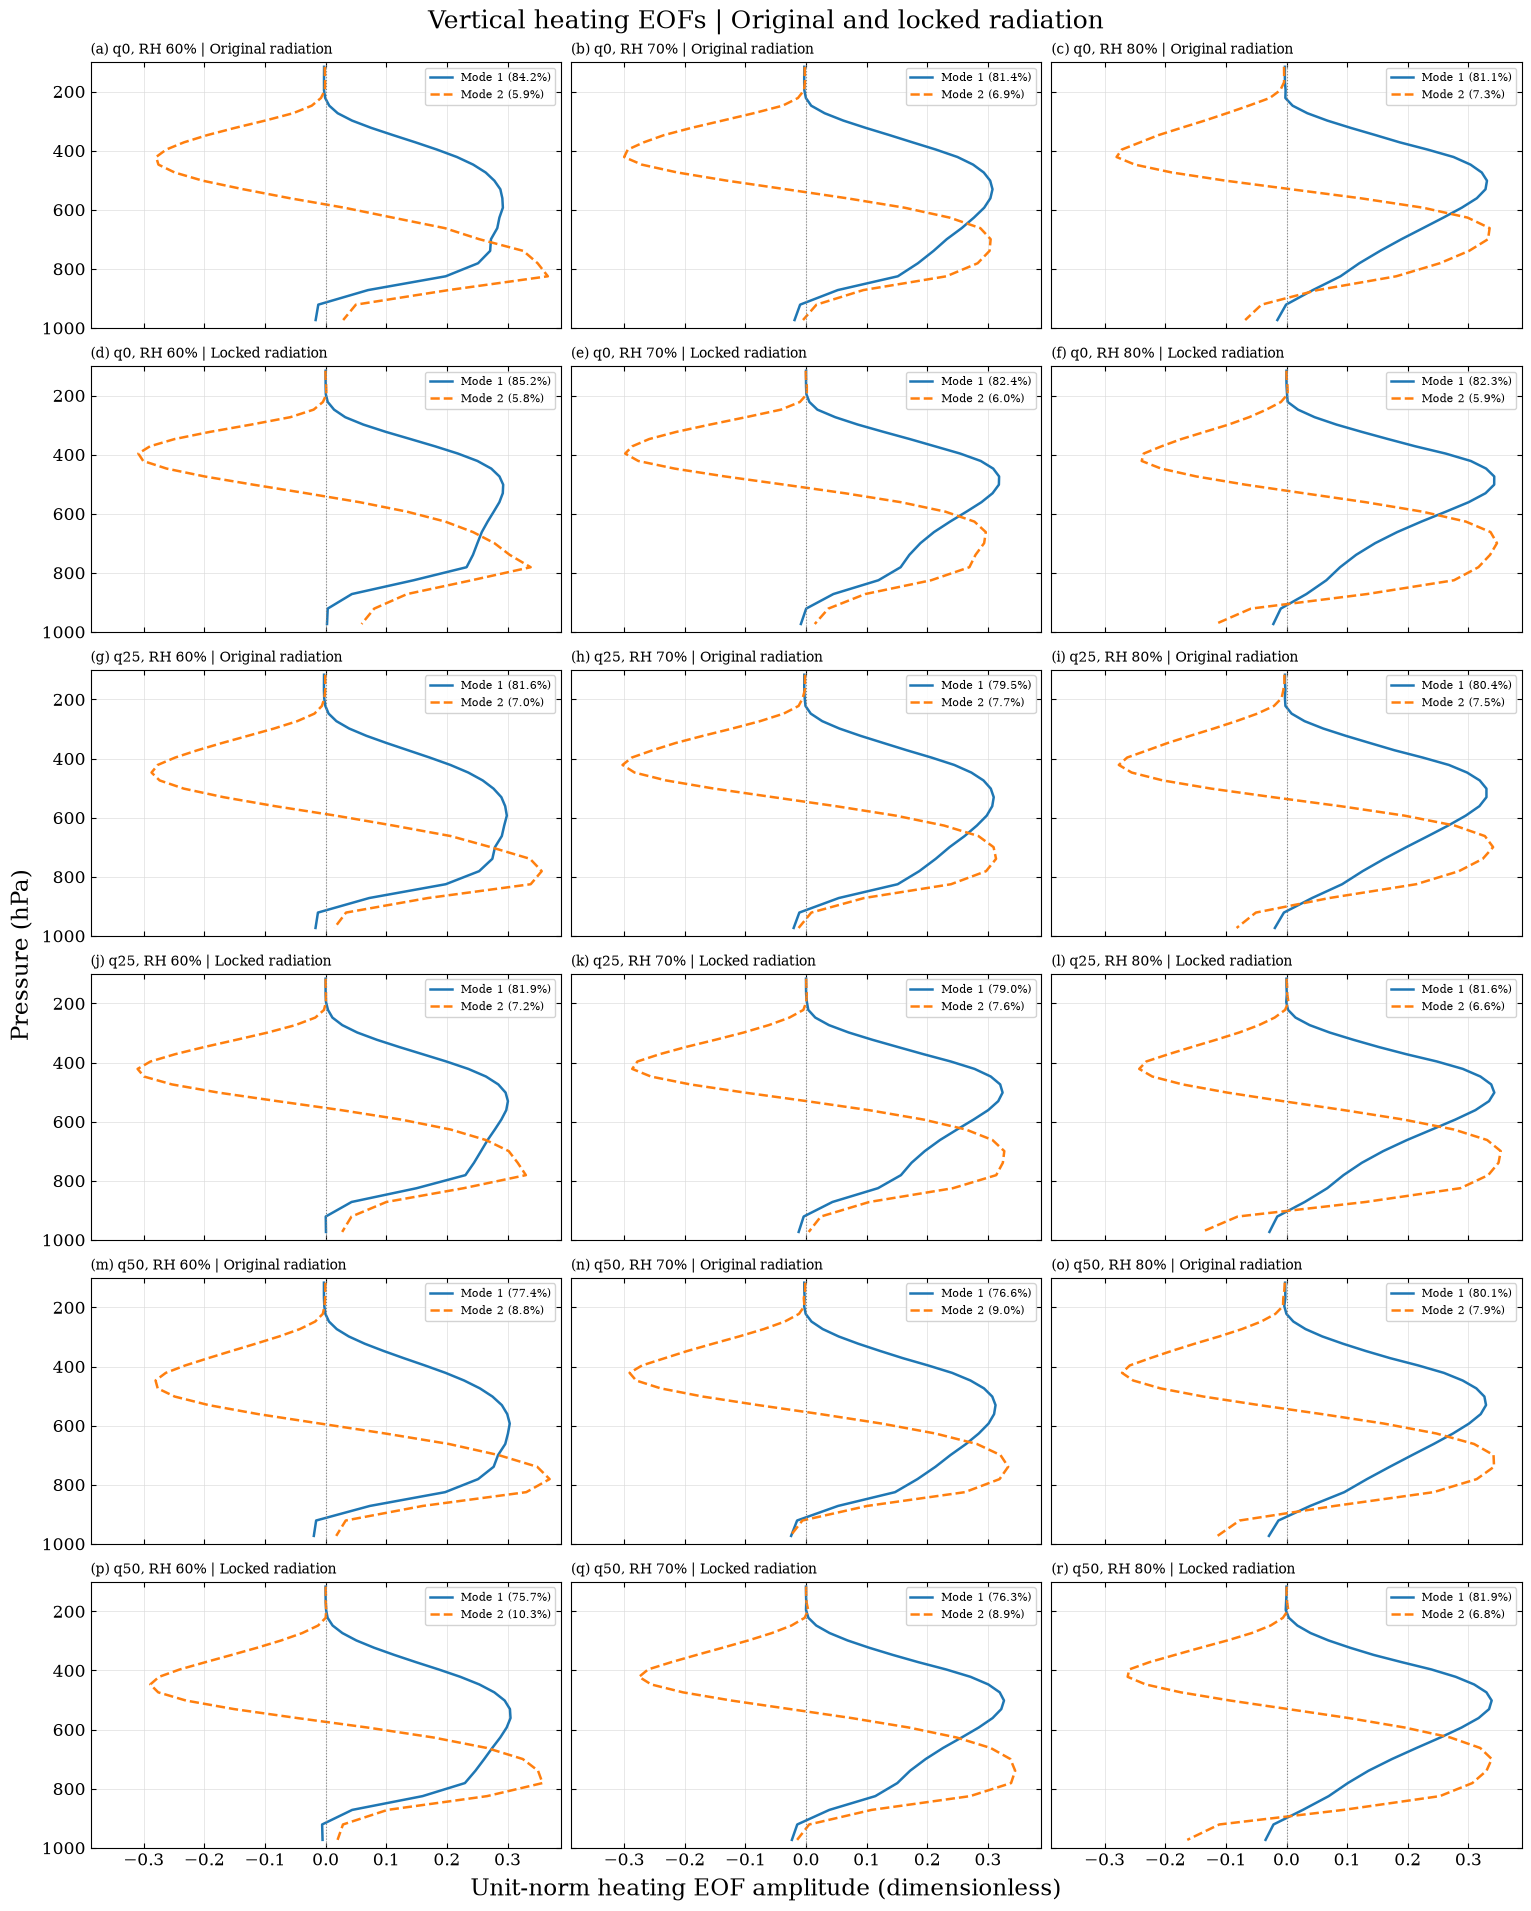

In [24]:
mode_panels = {}
mode_panel_labels = {}
for (qflux, rh, rad), name in experiment_lookup.items():
    if name not in aligned_modes:
        continue
    key = ((qflux, rad), rh)
    mode_panels[key] = aligned_modes[name]
    explained = mode_data[name]["explained_variance"]
    mode_panel_labels[key] = [
        f"Mode {mode} ({fraction:.1f}%)"
        for mode, fraction in zip(modes, explained)
    ]

figures["vertical_modes_comparison"], mode_axes = plot_profile_grid(
    mode_panels, absolute_titles, comparison_rows, rh_values,
    title="Vertical heating EOFs | Original and locked radiation",
    xlabel="Unit-norm heating EOF amplitude (dimensionless)",
    labels=["Mode 1", "Mode 2"], colors=MODE_COLORS,
    linestyles=MODE_LINESTYLES, panel_labels=mode_panel_labels,
    limits=MODE_LIMITS, symmetric=True,
)


## Convective and condensational heating variance

Each experiment panel contains both components: solid blue for convective
heating and dashed orange for condensational heating, identified in the legend.
Both curves use the same horizontal axis, and all experiment panels share its
limits. Values are the saved population variances in K² day⁻², with no
normalization or logarithm. Zeros are retained.

These profiles use pooled time/latitude/longitude samples, whereas the EOFs
use total-heating anomalies after time-mean removal at each grid point.
The variance of total heating also depends on component covariances.

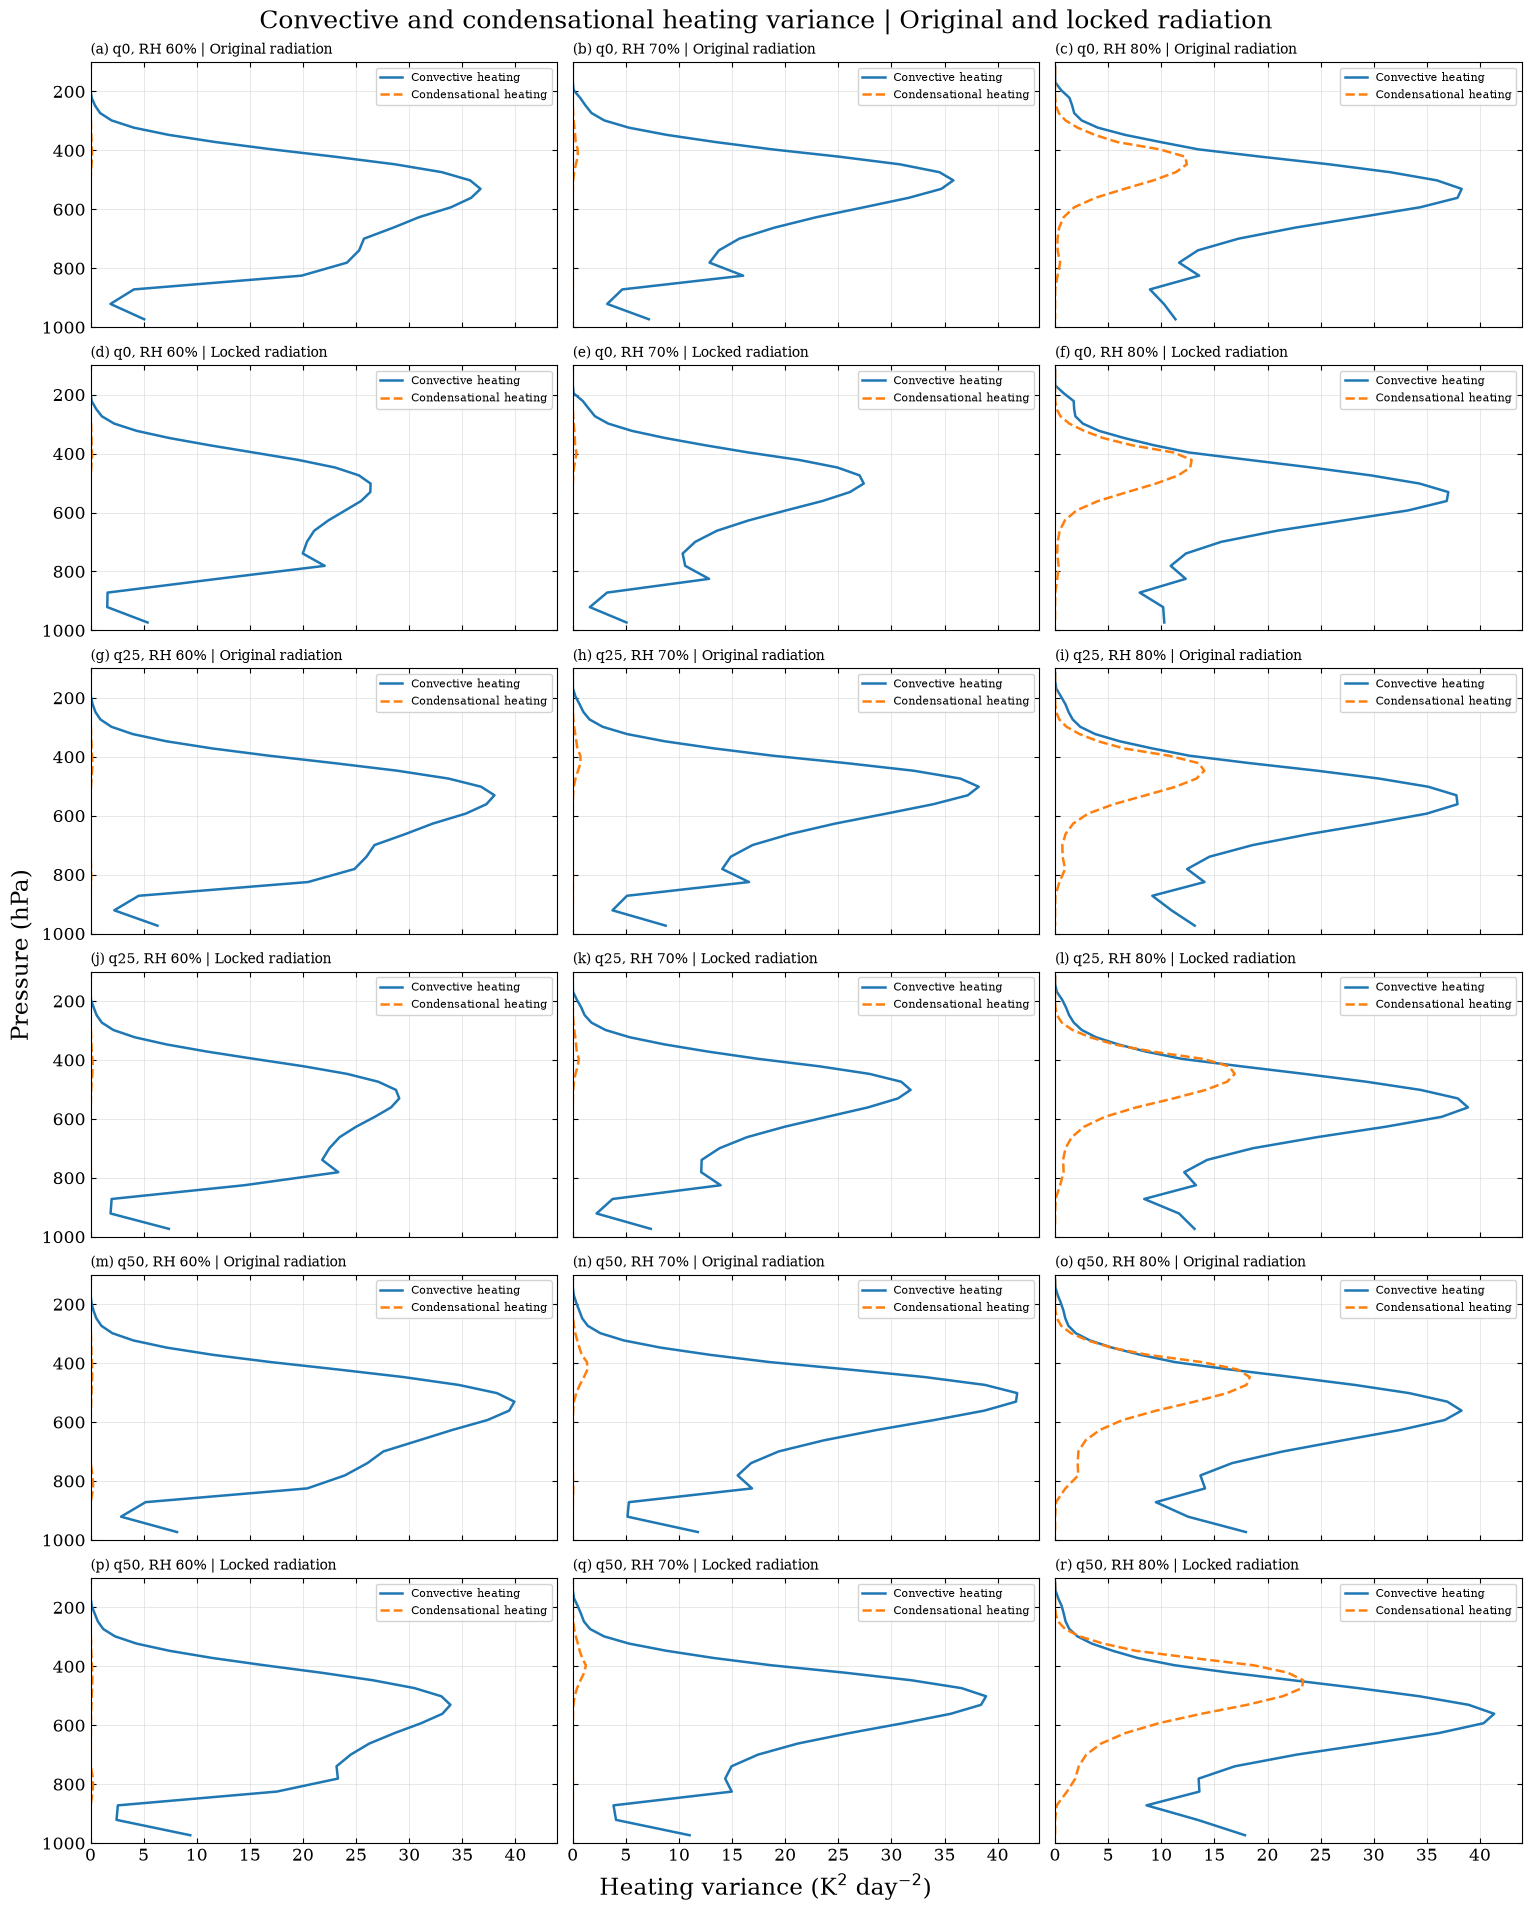

In [25]:
variance_panels = {
    ((qflux, rad), rh): np.stack([
        variance_data[name][field] for field, _, _ in COMPONENTS.values()
    ])
    for (qflux, rh, rad), name in experiment_lookup.items()
    if name in variance_data
}

figures["heating_variance_comparison"], variance_axes = plot_profile_grid(
    variance_panels, absolute_titles, comparison_rows, rh_values,
    title="Convective and condensational heating variance | Original and locked radiation",
    xlabel=r"Heating variance (K$^2$ day$^{-2}$)",
    labels=[label for _, label, _ in COMPONENTS.values()],
    colors=[color for _, _, color in COMPONENTS.values()],
    linestyles=["-", "--"], limits=VARIANCE_LIMITS,
)


## Optional figure export

Set **SAVE_FIGURES** to True to save the vertical EOF comparison and combined
heating variance comparison as PNG figures at 300 dpi. Export is disabled
by default.

In [26]:
SAVE_FIGURES = True
FIGURE_DIR = PROJECT_ROOT / "Figure" / "Heating_profiles"

if SAVE_FIGURES:
    FIGURE_DIR.mkdir(parents=True, exist_ok=True)
    for name, figure in figures.items():
        output_path = FIGURE_DIR / f"{name}.png"
        figure.savefig(output_path, dpi=300, bbox_inches="tight")
        print(f"Saved {output_path}")


Saved /home/b11209013/Isca_analysis/Figure/Heating_profiles/vertical_modes_comparison.png
Saved /home/b11209013/Isca_analysis/Figure/Heating_profiles/heating_variance_comparison.png
